In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
sns.set_theme(style="darkgrid", palette="deep")
pd.set_option("display.float_format","{:,.2f}".format)
print("pandas,matplotlib,seaborn loaded")


pandas,matplotlib,seaborn loaded


In [49]:
raw=pd.read_csv("superstore.csv"  ,  encoding="latin-1")
print(raw.shape)

(9994, 21)


#check missing values

In [50]:
print(raw.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


#check data types

In [51]:
print(raw.dtypes)

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


#check impossible numbers

In [52]:
print("Sales<=0:",(raw["Sales"]<=0).sum())
print("Quantity<=0",(raw["Quantity"]<=0).sum())
print("discount outside 0 to 1:",((raw["Discount"]<0) | (raw["Discount"]>1)).sum())

Sales<=0: 0
Quantity<=0 0
discount outside 0 to 1: 0


#check dates

In [53]:
order_dt=pd.to_datetime(raw["Order Date"], format="%m/%d/%Y",errors="coerce")
ship_dt=pd.to_datetime(raw["Ship Date"], format="%m/%d/%Y", errors="coerce")



In [54]:
print("bad order date:", order_dt.isnull().sum())
print("bad ship date:",  ship_dt.isnull().sum())
print("shipped before ordered", (ship_dt<order_dt).sum())

bad order date: 0
bad ship date: 0
shipped before ordered 0


#check duplicate rows

In [55]:
cols=[c for c in raw.columns if c!="Row ID"]

print("exact duplicates:",raw.duplicated(subset=cols).sum())



exact duplicates: 1


In [56]:
lower=raw[cols].astype(str).map(str.lower)

print("duplicates ignoring capitals:", lower.duplicated().sum())

duplicates ignoring capitals: 1


#look at the duplicate rows

In [57]:
dup_rows= raw[raw.duplicated(subset=cols, keep=False)]
print(dup_rows[["Row ID","Order ID","Product ID","Sales","Quantity","Profit"]])

      Row ID        Order ID       Product ID  Sales  Quantity  Profit
3405    3406  US-2014-150119  FUR-CH-10002965 281.37         2  -12.06
3406    3407  US-2014-150119  FUR-CH-10002965 281.37         2  -12.06


#check extra spaces in text columns

In [58]:
text_cols =  raw.select_dtypes(include="str").columns



for c in text_cols:
    n=(raw[c] !=raw[c].str.strip()).sum()
    print(c, ":",n)

Order ID : 0
Order Date : 0
Ship Date : 0
Ship Mode : 0
Customer ID : 0
Customer Name : 0
Segment : 0
Country : 0
City : 0
State : 0
Region : 0
Product ID : 0
Category : 0
Sub-Category : 0
Product Name : 16


#clean the data

In [59]:
clean = raw.copy()



for c in text_cols:
    clean[c]= clean[c].str.strip()


clean["Order Date"]= pd.to_datetime(raw["Order Date"], format="%m/%d/%Y")
clean["Ship Date"]  = pd.to_datetime(raw["Ship Date"],format="%m/%d/%Y")


clean["Postal Code"]= clean["Postal Code"].astype(str)

clean= clean.drop_duplicates(subset=cols,keep="first")


print(clean.shape)

(9993, 21)


#check Compare raw and clean totals

In [60]:
summary=pd.DataFrame({
    "rows":[len(raw),len(clean)],
    "total sales":[raw['Sales'].sum(),clean["Sales"].sum()],
    "total profit":[raw["Profit"].sum(),clean["Profit"].sum()],
    "total quantity":[raw["Quantity"].sum(),clean["Quantity"].sum()], 
},index=["raw","clean"])

print(summary.round(2))

       rows  total sales  total profit  total quantity
raw    9994 2,297,200.86    286,397.02           37873
clean  9993 2,296,919.49    286,409.08           37871


#check clean table itself

In [61]:
print("product name with spaces:", (clean["Product Name"] != clean["Product Name"].str.strip()).sum())
print("empty dates:",clean[["Order Date","Ship Date"]].isnull().sum())
print("shipped before ordered:",(clean["Ship Date"]<clean["Order Date"]).sum())
print("duplicates left:",clean.duplicated(subset=cols).sum())
print()
print(clean.dtypes)


product name with spaces: 0
empty dates: Order Date    0
Ship Date     0
dtype: int64
shipped before ordered: 0
duplicates left: 0

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


#part 2 analysis

# Q1: overall total and profit margin

In [62]:
total_orders= clean["Order ID"].nunique()
total_sales=round(clean["Sales"].sum(),2)
total_profit=round(clean["Profit"].sum(),2)
profit_margin=round(total_profit/total_sales*100,2)

print("total_orders:",total_orders)
print("total sales:",total_sales)
print("total profit:",total_profit)
print("profit margin%:",profit_margin)


total_orders: 5009
total sales: 2296919.49
total profit: 286409.08
profit margin%: 12.47


# category summary

In [63]:
q2 = clean.groupby("Category").agg(
    total_orders=("Order ID","nunique"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q2["profit_margin_pct"]=q2["total_profit"]/q2["total_sales"]*100
q2=q2.sort_values("total_profit",ascending=False).round(2)
print(q2)

          Category  total_orders  total_sales  total_profit  profit_margin_pct
2       Technology          1544   836,154.03    145,454.95              17.40
1  Office Supplies          3742   719,047.03    122,490.80              17.04
0        Furniture          1764   741,718.42     18,463.33               2.49


# region summary

In [64]:
q3=clean.groupby("Region").agg(
    total_orders=("Order ID","nunique"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q3["profit_margin_pct"]=q3["total_profit"]/q3["total_sales"]*100
q3=q3.sort_values("total_profit",ascending=False).round(2)
print(q3)

    Region  total_orders  total_sales  total_profit  profit_margin_pct
3     West          1611   725,457.82    108,418.45              14.94
1     East          1401   678,499.87     91,534.84              13.49
2    South           822   391,721.90     46,749.43              11.93
0  Central          1175   501,239.89     39,706.36               7.92


# segment summary

In [65]:
q4=clean.groupby("Segment").agg(
    total_orders=("Order ID","nunique"),
    total_customers=("Customer ID","nunique"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q4["profit_margin_pct"]=q4["total_profit"]/q4["total_sales"]*100
q4=q4.sort_values("total_profit",ascending=False).round(2)
print(q4)
print(q4[["total_orders","total_sales","total_profit"]].sum())

       Segment  total_orders  total_customers  total_sales  total_profit  \
0     Consumer          2586              409 1,161,401.34    134,119.21   
1    Corporate          1514              236   706,146.37     91,979.13   
2  Home Office           909              148   429,371.78     60,310.74   

   profit_margin_pct  
0              11.55  
1              13.03  
2              14.05  
total_orders       5,009.00
total_sales    2,296,919.49
total_profit     286,409.08
dtype: float64


# ship mode

In [66]:
q5=clean.groupby("Ship Mode").agg(
    total_orders=("Order ID","nunique"),
    total_sales=("Sales","sum")
).reset_index()

q5["avg_sales_per_order"]=q5["total_sales"]/q5["total_orders"]
q5=q5.sort_values("total_orders",ascending=False).round(2)
print(q5)

        Ship Mode  total_orders  total_sales  avg_sales_per_order
3  Standard Class          2994 1,357,934.37               453.55
2    Second Class           964   459,193.57               476.34
0     First Class           787   351,428.42               446.54
1        Same Day           264   128,363.12               486.22


# yearly summary

In [67]:
clean["Order year"]=clean["Order Date"].dt.year
clean["Order month"]=clean["Order Date"].dt.month

q6=clean.groupby("Order year").agg(
    total_orders=("Order ID","nunique"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q6["profit_margin_pct"]=q6["total_profit"]/q6["total_sales"]*100
q6=q6.round(2)
print(q6)
print(q6[["total_orders","total_sales","total_profit"]].sum())

   Order year  total_orders  total_sales  total_profit  profit_margin_pct
0        2014           969   483,966.13     49,556.03              10.24
1        2015          1038   470,532.51     61,618.60              13.10
2        2016          1315   609,205.60     81,795.17              13.43
3        2017          1687   733,215.26     93,439.27              12.74
total_orders       5,009.00
total_sales    2,296,919.50
total_profit     286,409.07
dtype: float64


# monthly summary

In [68]:
q7=clean[clean["Order year"]==2017].groupby("Order month").agg(
    total_orders=("Order ID","nunique"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q7=q7.round(2)
print(q7)

    Order month  total_orders  total_sales  total_profit
0             1            69    43,971.37      7,140.44
1             2            53    20,301.13      1,613.87
2             3           118    58,872.35     14,751.89
3             4           116    36,521.54        933.29
4             5           118    44,261.11      6,342.58
5             6           133    52,981.73      8,223.34
6             7           111    45,264.42      6,952.62
7             8           111    63,120.89      9,040.96
8             9           226    87,866.65     10,991.56
9            10           147    77,776.92      9,275.28
10           11           261   118,447.82      9,690.10
11           12           224    83,829.32      8,483.35


# Q8 Top 10 customers by sales

In [69]:
q8=clean.groupby(["Customer ID","Customer Name"]).agg(
    total_orders=("Order ID","nunique"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q8=q8.sort_values("total_sales",ascending=False).head(10).round(2)
print(q8)

    Customer ID       Customer Name  total_orders  total_sales  total_profit
700    SM-20320         Sean Miller             5    25,043.05     -1,980.74
741    TC-20980        Tamara Chand             5    19,052.22      8,981.32
621    RB-19360        Raymond Buch             6    15,117.34      6,976.10
730    TA-21385        Tom Ashbrook             4    14,595.62      4,703.79
6      AB-10105       Adrian Barton            10    14,473.57      5,444.81
434    KL-16645        Ken Lonsdale            12    14,175.23        806.86
669    SC-20095        Sanjit Chand             9    14,142.33      5,757.41
327    HL-15040        Hunter Lopez             6    12,873.30      5,622.43
683    SE-20110        Sanjit Engle            11    12,209.44      2,650.68
131    CC-12370  Christopher Conant             5    12,129.07      2,177.05


# q9 loss making sub categories

In [70]:
q9=clean.groupby(["Category","Sub-Category"]).agg(
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q9["profit_margin_pct"]=q9["total_profit"]/q9["total_sales"]*100
q9=q9.round(2)
q9=q9[q9["total_profit"]<0].sort_values("total_profit")
print(q9)

           Category Sub-Category  total_sales  total_profit  profit_margin_pct
3         Furniture       Tables   206,965.53    -17,725.48              -8.56
0         Furniture    Bookcases   114,880.00     -3,472.56              -3.02
12  Office Supplies     Supplies    46,673.54     -1,189.10              -2.55


# q10 top 10 products by profit

In [71]:
q10=clean.groupby(["Product ID","Product Name"]).agg(
    total_quantity=("Quantity","sum"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q10=q10.sort_values("total_profit",ascending=False).head(10).round(2)
print(q10)

           Product ID                                       Product Name  \
1640  TEC-CO-10004722              Canon imageCLASS 2200 Advanced Copier   
787   OFF-BI-10003527  Fellowes PB500 Electric Punch Plastic Comb Bin...   
1630  TEC-CO-10001449               Hewlett Packard LaserJet 3310 Copier   
1637  TEC-CO-10003763                 Canon PC1060 Personal Laser Copier   
1657  TEC-MA-10001127  HP Designjet T520 Inkjet Large Format Printer ...   
1693  TEC-MA-10003979                  Ativa V4110MDD Micro-Cut Shredder   
1656  TEC-MA-10001047   3D Systems Cube Printer, 2nd Generation, Magenta   
1541  TEC-AC-10002049  Plantronics Savi W720 Multi-Device Wireless He...   
692   OFF-BI-10001120               Ibico EPK-21 Electric Binding System   
1643  TEC-MA-10000045                  Zebra ZM400 Thermal Label Printer   

      total_quantity  total_sales  total_profit  
1640              20    61,599.82     25,199.93  
787               31    27,453.38      7,753.04  
1630         

# q11 Discount bands

In [72]:
clean["Discount Band"]= np.where(clean["Discount"]==0,  "NO DISCOUNT",
                        np.where(clean["Discount"]<=0.2,  "UP TO 20%", "ABOVE 20%"))
q11=clean.groupby("Discount Band").agg(
    order_lines=("Row ID","count"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()

q11['profit_margin_pct']=q11["total_profit"]/q11["total_sales"]*100
q11["avg_profit_per_line"]=q11["total_profit"]/q11["order_lines"]
q11=q11.sort_values("profit_margin_pct",ascending=False).round(2)
print(q11)

  Discount Band  order_lines  total_sales  total_profit  profit_margin_pct  \
1   NO DISCOUNT         4798 1,087,908.47    320,987.60              29.51   
2     UP TO 20%         3803   846,522.24    100,785.47              11.91   
0     ABOVE 20%         1392   362,488.78   -135,364.00             -37.34   

   avg_profit_per_line  
1                66.90  
2                26.50  
0               -97.24  


# Q12 Loss-making order lines    
how many lines lose money, their total loss, their share of all lines, and their average discount.

In [73]:
loss = clean[clean["Profit"] < 0]

print("Loss lines:", len(loss))
print("Total loss:", round(loss["Profit"].sum(), 2))
print("Loss lines %:", round(len(loss) / len(clean) * 100, 2))
print("Average discount % on loss lines:", round(loss["Discount"].mean() * 100, 1))


Loss lines: 1870
Total loss: -156119.23
Loss lines %: 18.71
Average discount % on loss lines: 48.1


# Q13: states with negative total profit

In [74]:
q13= clean.groupby("State").agg(
    total_orders=("Order ID","nunique"),
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")
).reset_index()
q13["profit_margin_pct"]=q13["total_profit"]/ q13["total_sales"]*100
q13=q13.round(2)
q13=q13[q13["total_profit"]<0].sort_values("total_profit")
print(q13)

             State  total_orders  total_sales  total_profit  profit_margin_pct
41           Texas           487   170,188.05    -25,729.36             -15.12
33            Ohio           236    77,976.76    -16,959.32             -21.75
36    Pennsylvania           288   116,511.91    -15,559.96             -13.35
11        Illinois           276    80,166.10    -12,607.89             -15.73
31  North Carolina           136    55,603.16     -7,490.91             -13.47
4         Colorado            79    32,108.12     -6,527.86             -20.33
40       Tennessee            91    30,661.87     -5,341.69             -17.42
1          Arizona           108    35,282.00     -3,427.92              -9.72
8          Florida           200    89,473.71     -3,399.30              -3.80
35          Oregon            56    17,431.15     -1,190.47              -6.83


# Q14: yearly sales growth

In [75]:
q14=clean.groupby('Order year').agg(
    total_sales=("Sales","sum")
).reset_index()

q14["previous_year_sales"]=q14["total_sales"].shift(1)
q14["growth_pct"]=(q14["total_sales"]-q14["previous_year_sales"])/q14["previous_year_sales"]*100
q14=q14.round(2)
print(q14)

   Order year  total_sales  previous_year_sales  growth_pct
0        2014   483,966.13                  NaN         NaN
1        2015   470,532.51           483,966.13       -2.78
2        2016   609,205.60           470,532.51       29.47
3        2017   733,215.26           609,205.60       20.36


# Q15: top 3 products by sales in each category
RANK() OVER (PARTITION BY category ...) gave each product a rank within its category, and in pandas groupby with rank does that.

In [76]:
pro_sales=clean.groupby(["Category","Product ID","Product Name"]).agg(
    total_sales=("Sales","sum")
).reset_index()

pro_sales["sales_rank"]=pro_sales.groupby("Category")["total_sales"].rank(method="min",ascending=False)
q15=pro_sales[pro_sales["sales_rank"]<=3].sort_values(["Category","sales_rank"]).round(2)
print(q15)

             Category       Product ID  \
82          Furniture  FUR-CH-10002024   
49          Furniture  FUR-BO-10004834   
363         Furniture  FUR-TA-10003473   
787   Office Supplies  OFF-BI-10003527   
701   Office Supplies  OFF-BI-10001359   
667   Office Supplies  OFF-BI-10000545   
1640       Technology  TEC-CO-10004722   
1669       Technology  TEC-MA-10002412   
1630       Technology  TEC-CO-10001449   

                                           Product Name  total_sales  \
82         HON 5400 Series Task Chairs for Big and Tall    21,870.58   
49    Riverside Palais Royal Lawyers Bookcase, Royal...    15,610.97   
363          Bretford Rectangular Conference Table Tops    12,995.29   
787   Fellowes PB500 Electric Punch Plastic Comb Bin...    27,453.38   
701          GBC DocuBind TL300 Electric Binding System    19,823.48   
667    GBC Ibimaster 500 Manual ProClick Binding System    19,024.50   
1640              Canon imageCLASS 2200 Advanced Copier    61,599.82   
166

# Q16: monthly sales and running total for 2017

In [77]:
q16=clean[clean["Order year"]==2017].groupby("Order month").agg(
    monthly_sales=("Sales","sum")
).reset_index()

q16["running_total_sales"]=q16["monthly_sales"].cumsum()
q16=q16.round(2)
print(q16)

    Order month  monthly_sales  running_total_sales
0             1      43,971.37            43,971.37
1             2      20,301.13            64,272.51
2             3      58,872.35           123,144.86
3             4      36,521.54           159,666.40
4             5      44,261.11           203,927.51
5             6      52,981.73           256,909.23
6             7      45,264.42           302,173.65
7             8      63,120.89           365,294.54
8             9      87,866.65           453,161.19
9            10      77,776.92           530,938.11
10           11     118,447.82           649,385.94
11           12      83,829.32           733,215.26


# Q17: delivery days by ship mode

In [78]:
clean["delivery days"]=(clean["Ship Date"]-clean["Order Date"]).dt.days

q17=clean.groupby("Ship Mode").agg(
    total_lines=("Row ID","count"),
    avg_delivery_days=("delivery days","mean"),
    fastest_days=("delivery days","min"),
    slowest_days=("delivery days","max")
).reset_index()

q17=q17.sort_values("avg_delivery_days").round(2)
print(q17)

        Ship Mode  total_lines  avg_delivery_days  fastest_days  slowest_days
1        Same Day          543               0.04             0             1
0     First Class         1538               2.18             1             4
2    Second Class         1945               3.24             1             5
3  Standard Class         5967               5.01             3             7


# Q18: customer groups by total sales

In [79]:
cust = clean.groupby("Customer ID").agg(
    cust_sales=("Sales", "sum"),
    cust_profit=("Profit", "sum")
).reset_index()

cust["customer_group"] = np.where(cust["cust_sales"] >= 5000, "HIGH",
                         np.where(cust["cust_sales"] >= 2000, "MEDIUM", "LOW"))

q18 = cust.groupby("customer_group").agg(
    total_customers=("Customer ID", "nunique"),
    total_sales=("cust_sales", "sum"),
    total_profit=("cust_profit", "sum")
).reset_index()

q18["sales_share_pct"] = q18["total_sales"] / clean["Sales"].sum() * 100
q18 = q18.sort_values("total_sales", ascending=False).round(2)

print(q18)


  customer_group  total_customers  total_sales  total_profit  sales_share_pct
2         MEDIUM              323 1,021,789.70    109,245.68            44.49
0           HIGH              117   911,958.27    140,313.08            39.70
1            LOW              353   363,171.52     36,850.32            15.81


# Q19: one-time vs repeat customers

In [80]:
cust_orders=clean.groupby("Customer ID").agg(
    cust_orders=("Order ID","nunique"),
    cust_sales=("Sales","sum")
).reset_index()

cust_orders["customer_type"]=np.where(cust_orders["cust_orders"]==1,"ONE TIME","REPEAT")

q19=cust_orders.groupby("customer_type").agg(
    total_customers=("Customer ID","nunique"),
    total_sales=("cust_sales","sum")
).reset_index()

q19["customer_share_pct"]=q19["total_customers"]/clean["Customer ID"].nunique()*100
q19["sales_share_pct"]=q19["total_sales"]/clean["Sales"].sum()*100
q19=q19.sort_values("total_customers",ascending=False).round(2)
print(q19)

  customer_type  total_customers  total_sales  customer_share_pct  \
1        REPEAT              781 2,291,751.85               98.49   
0      ONE TIME               12     5,167.64                1.51   

   sales_share_pct  
1            99.78  
0             0.22  


# EDA 1: summary statistics

In [81]:
num_cols=["Sales","Quantity","Discount","Profit","delivery days"]
print(clean[num_cols].describe().round(2))

          Sales  Quantity  Discount    Profit  delivery days
count  9,993.00  9,993.00  9,993.00  9,993.00       9,993.00
mean     229.85      3.79      0.16     28.66           3.96
std      623.28      2.23      0.21    234.27           1.75
min        0.44      1.00      0.00 -6,599.98           0.00
25%       17.28      2.00      0.00      1.73           3.00
50%       54.48      3.00      0.20      8.67           4.00
75%      209.94      5.00      0.20     29.36           5.00
max   22,638.48     14.00      0.80  8,399.98           7.00


# EDA 2: distributions of Sales and Profit

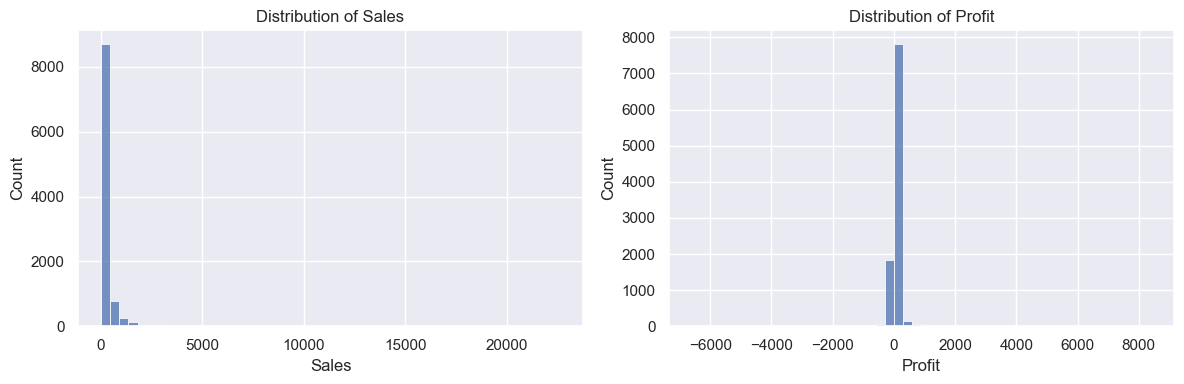

In [82]:
fig,axes= plt.subplots(1,2, figsize=(12,4))

sns.histplot(clean["Sales"],bins=50,ax=axes[0])
axes[0].set_title("Distribution of Sales")

sns.histplot(clean["Profit"],bins=50,ax=axes[1])
axes[1].set_title("Distribution of Profit")

plt.tight_layout()
plt.show()



# EDA 3: percentiles and zoomed distributions

        Sales  Profit
0.01     2.29 -319.28
0.25    17.28    1.73
0.50    54.48    8.67
0.75   209.94   29.36
0.95   957.03  168.47
0.99 2,481.94  580.67


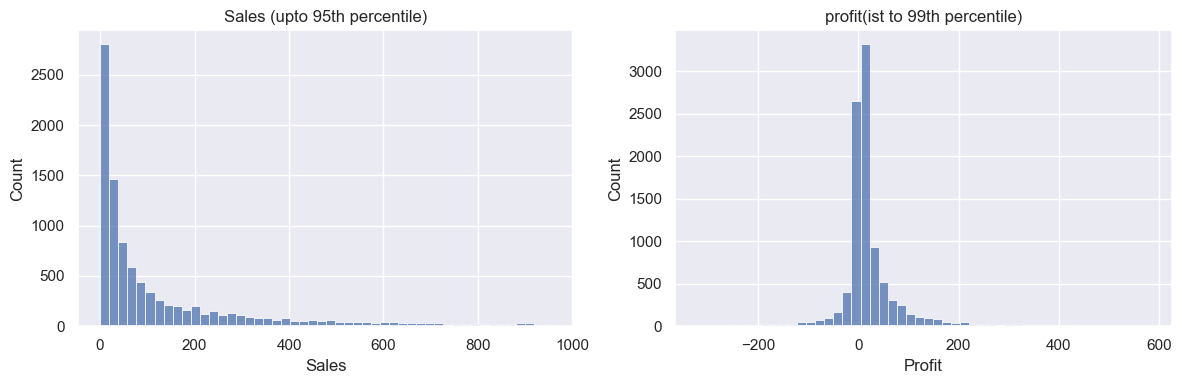

In [83]:
print(clean[["Sales","Profit"]].quantile([0.01,0.25,0.5,0.75,0.95,0.99]).round(2))

sales_cut=clean["Sales"].quantile(0.95)
profit_low=clean["Profit"].quantile(0.01)
profit_high=clean["Profit"].quantile(0.99)

zoom_sales=clean[clean["Sales"]<=sales_cut]
zoom_profit=clean[(clean["Profit"]>=profit_low)&(clean["Profit"]<=profit_high)]

fig, axes = plt.subplots(1,2 , figsize=(12,4))

sns.histplot(zoom_sales["Sales"],bins=50,ax=axes[0])
axes[0].set_title("Sales (upto 95th percentile)")

sns.histplot(zoom_profit["Profit"],bins=50,ax=axes[1])
axes[1].set_title("profit(ist to 99th percentile)")

plt.tight_layout()
plt.show()

# EDA 4: correlation between discount and profit

          Sales  Quantity  Discount  Profit
Sales      1.00      0.20     -0.03    0.48
Quantity   0.20      1.00      0.01    0.07
Discount  -0.03      0.01      1.00   -0.22
Profit     0.48      0.07     -0.22    1.00


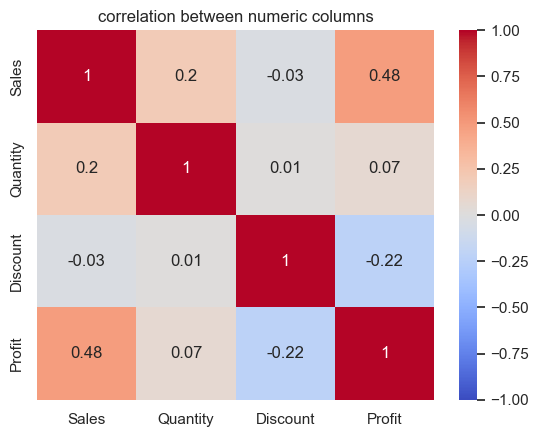

In [84]:

corr_cols=["Sales","Quantity","Discount","Profit"]
corr=clean[corr_cols].corr().round(2)
print(corr)

plt.Figure(figsize=(6,4))

sns.heatmap(corr,annot=True,cmap="coolwarm",vmin=-1,vmax=1)
plt.title("correlation between numeric columns")
plt.show()


# EDA 5: four key charts

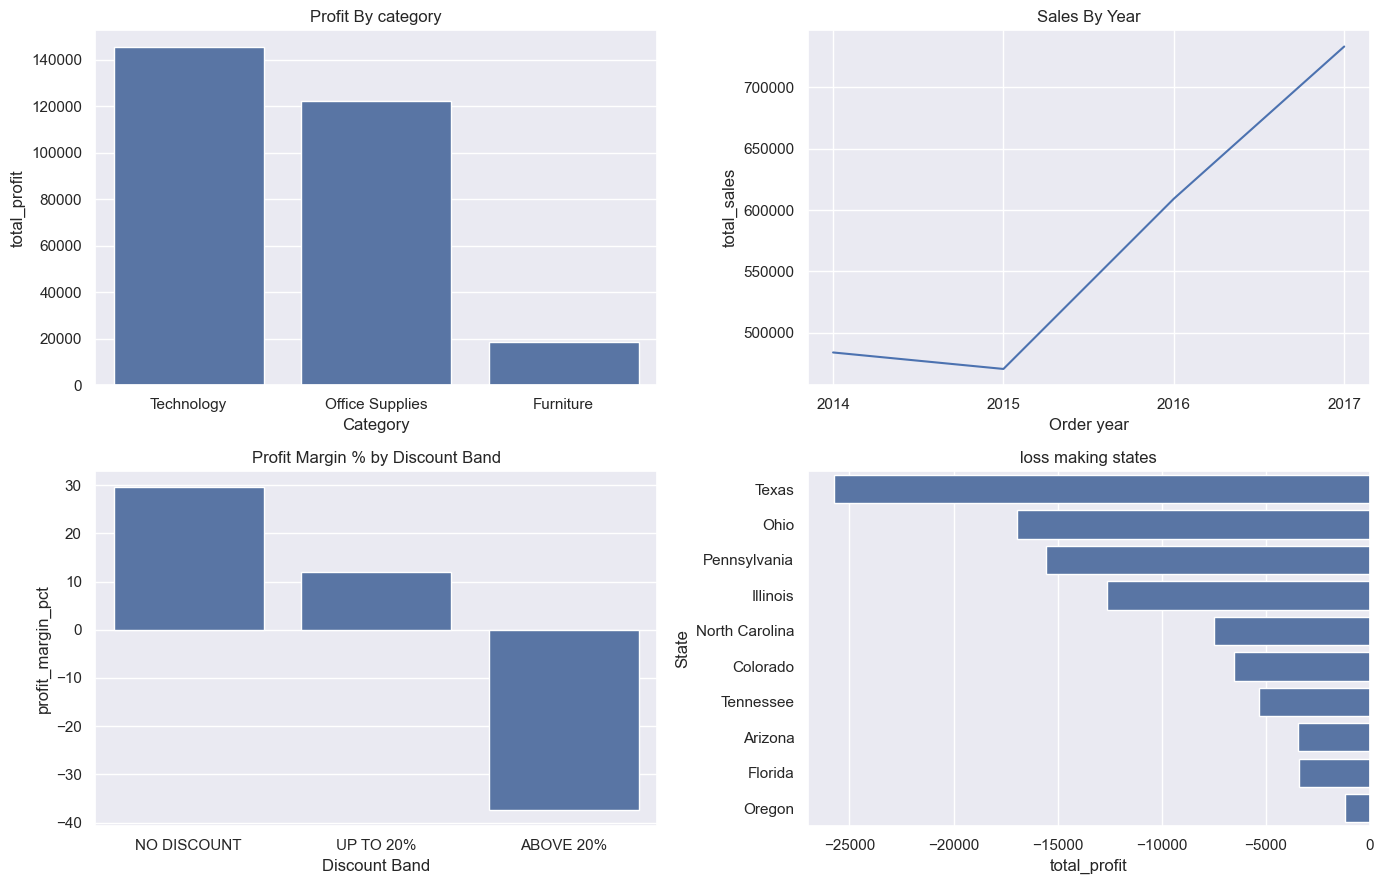

In [91]:
import os
os.makedirs("images", exist_ok=True)

fig,axes=plt.subplots(2,2,figsize=(14,9))

sns.barplot(data=q2,x="Category",y="total_profit",ax=axes[0,0])
axes[0,0].set_title("Profit By category")

sns.lineplot(data=q6,x="Order year",y="total_sales",markers="o",ax=axes[0,1])
axes[0,1].set_title("Sales By Year")
axes[0,1].set_xticks(q6["Order year"])

sns.barplot(data=q11,x="Discount Band",y="profit_margin_pct",ax=axes[1,0])
axes[1,0].set_title("Profit Margin % by Discount Band")

sns.barplot(data=q13,x="total_profit",y="State",ax=axes[1,1])
axes[1,1].set_title("loss making states")

plt.tight_layout()
plt.savefig("images/key_findings.png", dpi=150)
plt.show()

## Key findings

1. **Furniture** sells 741,718.42, almost as much as Office Supplies, but its margin is only 2.49%, against about 17% for Technology (17.40%) and Office Supplies (17.04%).
2. Lines discounted above 20% have a margin of -37.34% and lose about 97 per line (-97.24), while lines with no discount earn 29.51%.
3. **10 states lose money**, led by **Texas (-25,729) and Ohio (-16,959)**.
4. The loss-making sub-categories are **Tables (-17,725), Bookcases (-3,473) and Supplies (-1,189).**
5. **Sales fell 2.78% in 2015, then grew every year to 733,215 in 2017.**

## Recommendations

1. **Cap discounts at 20%.** Lines above 20% lost 135,364 in total, more than the 100,785 profit made by the up-to-20% band. Discount and profit are also negatively correlated (-0.22), and discounts bring no extra sales or quantity.
2. **Review pricing and discounts in the loss-making states**, starting with Texas, Ohio, Pennsylvania and Illinois, which have the largest losses.
3. **Review Furniture**, especially Tables and Bookcases, which lose about 21,200 together. Check supplier costs, prices and the discounts given on these products.